# Objective 2.2: Multiple Linear Regression for Match Goals Scored
**Role 3 Technical Deliverable**  
**Dataset**: `lr22_team_match_208.csv` ($N = 208$)  
**Target**: `goals_scored` (Team goals scored per match after extra time, excluding shoot-outs)

### Methodological Constraints & Pre-Match Integrity:
1. All explanatory variables are computed strictly prior to kick-off.
2. Maximum 4 conceptual overlaps with LR 2.1 (FIFA Rank, Squad Value, Host Nation, Stage).
3. Model selection via exhaustive subset search (AIC/BIC) and 10-fold cross-validation.

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error

# Visualization setup
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid', palette='muted')

# Load dataset
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
df = pd.read_csv(ROOT / 'data' / 'lr22_team_match_208.csv')
print('Dataset Shape:', df.shape)
df.head()

Dataset Shape: (208, 12)


,match_id,team,opponent,team_gf_pg,opp_ga_pg,opp_gf_pg,team_log_rank,opp_log_rank,team_log_value,is_host_home,is_knockout,goals_scored
0,1,Mexico,South Africa,1.3,1.3,1.3,2.639057,4.094345,5.256714,1,0,2
1,1,South Africa,Mexico,1.3,1.3,1.3,4.094345,2.639057,3.896909,0,0,0
2,2,South Korea,Czech Republic,1.3,1.3,1.3,3.218876,3.688879,4.934834,0,0,2
3,2,Czech Republic,South Korea,1.3,1.3,1.3,3.688879,3.218876,5.237399,0,0,1
4,3,Canada,Bosnia & Herzegovina,1.3,1.3,1.3,3.401197,4.158883,5.291544,1,0,1


In [2]:
# Target Variable Inspection
y = df['goals_scored']
print('--- Target Variable Summary (goals_scored) ---')
print(y.describe())
print(f'Zero goals count: {(y == 0).sum()} ({(y == 0).mean():.1%})')
print(f'Sample Mean: {y.mean():.4f} | Sample Variance: {y.var():.4f}')

--- Target Variable Summary (goals_scored) ---
count    208.000000
mean       1.480769
std        1.393434
min        0.000000
25%        0.000000
50%        1.000000
75%        2.000000
max        7.000000
Name: goals_scored, dtype: float64
Zero goals count: 55 (26.4%)
Sample Mean: 1.4808 | Sample Variance: 1.9417


In [3]:
# Full Model & VIF Multicollinearity Diagnostics
candidate_features = [
    'team_gf_pg', 'opp_ga_pg', 'opp_gf_pg',
    'team_log_rank', 'opp_log_rank', 'team_log_value',
    'is_host_home', 'is_knockout'
]
X_full = df[candidate_features]
X_full_const = sm.add_constant(X_full)

# Calculate VIF
vif_records = []
for i, col in enumerate(candidate_features):
    vif_val = variance_inflation_factor(X_full_const.values, i + 1)
    vif_records.append({'Feature': col, 'VIF': vif_val})
vif_df = pd.DataFrame(vif_records).sort_values(by='VIF', ascending=False)
print('--- Multicollinearity (VIF) ---')
print(vif_df.to_string(index=False))

# Full OLS fit
full_ols = sm.OLS(y, X_full_const).fit()
print(full_ols.summary())

--- Multicollinearity (VIF) ---
       Feature      VIF
team_log_value 3.026368
 team_log_rank 2.844623
  opp_log_rank 1.698158
    team_gf_pg 1.649856
   is_knockout 1.598015
     opp_gf_pg 1.537213
     opp_ga_pg 1.364943
  is_host_home 1.052013
                            OLS Regression Results                            
Dep. Variable:           goals_scored   R-squared:                       0.306
Model:                            OLS   Adj. R-squared:                  0.278
Method:                 Least Squares   F-statistic:                     10.96
Date:                Thu, 15 Oct 2026   Prob (F-statistic):           8.85e-13
Time:                        10:59:10   Log-Likelihood:                -325.67
No. Observations:                 208   AIC:                             669.3
Df Residuals:                     199   BIC:                             699.4
Df Model:                           8                                         
Covariance Type:            nonrobust    

In [4]:
# Best-Subset Selection & 10-Fold CV Validation
models_dict = {
    'Full (k=8)': candidate_features,
    'Optimal AIC (k=6)': ['team_gf_pg', 'opp_ga_pg', 'team_log_rank', 'opp_log_rank', 'team_log_value', 'is_host_home'],
    'Parsimonious (k=4)': ['opp_ga_pg', 'opp_log_rank', 'team_log_value', 'is_host_home'],
    'Core Quality (k=3)': ['opp_log_rank', 'team_log_value', 'is_host_home']
}

kf = KFold(n_splits=10, shuffle=True, random_state=42)
cv_summary = []

for name, feats in models_dict.items():
    X = sm.add_constant(df[feats])
    fit_m = sm.OLS(y, X).fit()
    cv_scores = []
    for tr, te in kf.split(df):
        m_tr = sm.OLS(y.iloc[tr], sm.add_constant(df.iloc[tr][feats])).fit()
        preds = m_tr.predict(sm.add_constant(df.iloc[te][feats]))
        cv_scores.append(np.sqrt(mean_squared_error(y.iloc[te], preds)))
    cv_summary.append({
        'Model': name,
        'k': len(feats),
        'R2': fit_m.rsquared,
        'Adj_R2': fit_m.rsquared_adj,
        'AIC': fit_m.aic,
        'BIC': fit_m.bic,
        '10-Fold CV RMSE': np.mean(cv_scores)
    })

pd.DataFrame(cv_summary)

,Model,k,R2,Adj_R2,AIC,BIC,10-Fold CV RMSE
0,Full (k=8),8,0.305939,0.278037,669.331989,699.369832,1.203012
1,Optimal AIC (k=6),6,0.304552,0.283793,665.747233,689.110000,1.191001
2,Parsimonious (k=4),4,0.283630,0.269515,667.912443,684.600133,1.196712
3,Core Quality (k=3),3,0.271563,0.260851,669.387098,682.737250,1.196661


In [5]:
# Final Selected Model (k=6) & Robust HC3 Standard Errors
opt_features = ['team_gf_pg', 'opp_ga_pg', 'team_log_rank', 'opp_log_rank', 'team_log_value', 'is_host_home']
X_opt_const = sm.add_constant(df[opt_features])
final_model = sm.OLS(y, X_opt_const).fit()
final_model_hc3 = final_model.get_robustcov_results(cov_type='HC3')

summary_coefs = pd.DataFrame({
    'Coef': final_model.params,
    'OLS_StdErr': final_model.bse,
    'OLS_p': final_model.pvalues,
    'HC3_StdErr': final_model_hc3.bse,
    'HC3_p': final_model_hc3.pvalues
})
print('--- Classical OLS vs HC3 Robust Standard Errors ---')
print(summary_coefs.round(4))
print(final_model.summary())

--- Classical OLS vs HC3 Robust Standard Errors ---
                  Coef  OLS_StdErr   OLS_p  HC3_StdErr   HC3_p
const          -0.7474      0.9791  0.4461      0.8791  0.3963
team_gf_pg     -0.3972      0.2151  0.0663      0.2015  0.0501
opp_ga_pg       0.4010      0.2156  0.0644      0.2709  0.1405
team_log_rank  -0.2263      0.1204  0.0616      0.1002  0.0250
opp_log_rank    0.2693      0.0826  0.0013      0.0867  0.0022
team_log_value  0.3862      0.1170  0.0011      0.1117  0.0007
is_host_home    0.8022      0.3464  0.0216      0.4026  0.0477
                            OLS Regression Results                            
Dep. Variable:           goals_scored   R-squared:                       0.305
Model:                            OLS   Adj. R-squared:                  0.284
Method:                 Least Squares   F-statistic:                     14.67
Date:                Thu, 15 Oct 2026   Prob (F-statistic):           7.09e-14
Time:                        10:59:10   Log-Likel

In [6]:
# Regression Diagnostic Suite
residuals = final_model.resid
fitted = final_model.fittedvalues

# Diagnostic tests
shapiro_w, shapiro_p = stats.shapiro(residuals)
jb_stat, jb_p, skew, kurt = sm.stats.jarque_bera(residuals)
bp_stat, bp_p = het_breuschpagan(residuals, final_model.model.exog)[:2]
dw_stat = durbin_watson(residuals)

print(f'Shapiro-Wilk W: {shapiro_w:.4f} (p = {shapiro_p:.4e})')
print(f'Jarque-Bera JB: {jb_stat:.4f} (p = {jb_p:.4e}, Skewness = {skew:.3f}, Kurtosis = {kurt:.3f})')
print(f'Breusch-Pagan LM: {bp_stat:.4f} (p = {bp_p:.4f})')
print(f'Durbin-Watson DW: {dw_stat:.4f}')

Shapiro-Wilk W: 0.9613 (p = 1.8883e-05)
Jarque-Bera JB: 45.8365 (p = 1.1136e-10, Skewness = 0.784, Kurtosis = 4.682)
Breusch-Pagan LM: 20.3025 (p = 0.0024)
Durbin-Watson DW: 1.8200


Subsets searched: 255
 k                                                                                   variables        AIC   Adj_R2
 6            team_gf_pg, opp_ga_pg, team_log_rank, opp_log_rank, team_log_value, is_host_home 665.747233 0.283793
 5                        opp_ga_pg, team_log_rank, opp_log_rank, team_log_value, is_host_home 667.246066 0.275249
 5                       team_gf_pg, team_log_rank, opp_log_rank, team_log_value, is_host_home 667.294161 0.275081
 5                           team_gf_pg, opp_ga_pg, opp_log_rank, team_log_value, is_host_home 667.372093 0.274810
 7 team_gf_pg, opp_ga_pg, opp_gf_pg, team_log_rank, opp_log_rank, team_log_value, is_host_home 667.537164 0.280938

Largest Cook's distance: 0.137
written: figures/lr22/report_figure_LR22.png


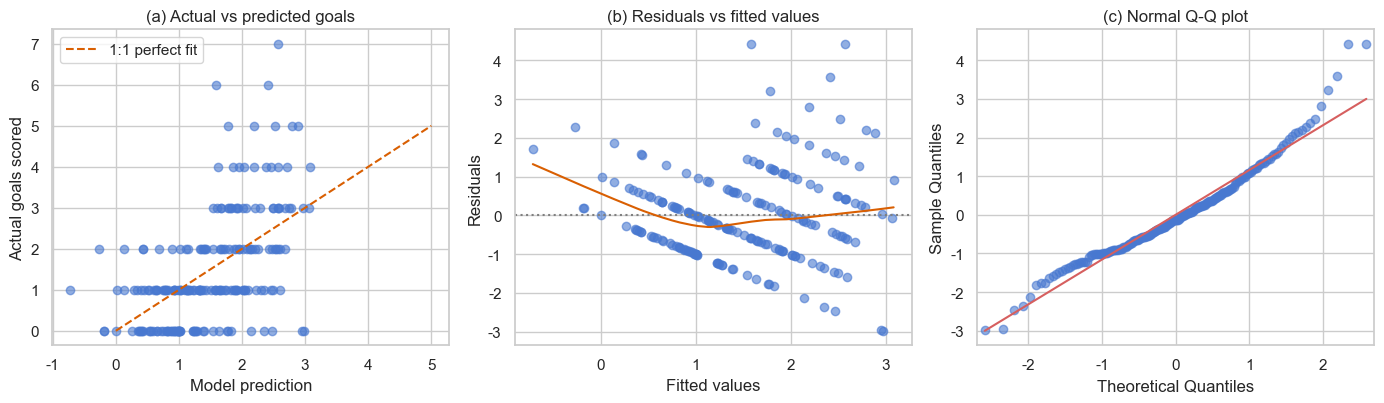

In [7]:
# Exhaustive best-subset search, influence check and the report's Figure 2
from itertools import combinations
from statsmodels.stats.outliers_influence import OLSInfluence

subset_rows = []
for k in range(1, len(candidate_features) + 1):
    for combo in combinations(candidate_features, k):
        fit_s = sm.OLS(y, sm.add_constant(df[list(combo)])).fit()
        subset_rows.append({'k': k, 'variables': ', '.join(combo), 'AIC': fit_s.aic, 'Adj_R2': fit_s.rsquared_adj})
subsets = pd.DataFrame(subset_rows).sort_values('AIC').reset_index(drop=True)
print(f'Subsets searched: {len(subsets)}')
print(subsets.head(5).to_string(index=False))

cooks_d = OLSInfluence(final_model).cooks_distance[0]
print(f"\nLargest Cook's distance: {cooks_d.max():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
axes[0].scatter(fitted, y, alpha=0.6)
axes[0].plot([0, 5], [0, 5], '--', color='#d95f02', label='1:1 perfect fit')
axes[0].set(title='(a) Actual vs predicted goals', xlabel='Model prediction', ylabel='Actual goals scored')
axes[0].legend(loc='upper left')
axes[1].scatter(fitted, residuals, alpha=0.6)
axes[1].axhline(0, color='grey', linestyle=':')
smooth = sm.nonparametric.lowess(residuals, fitted)
axes[1].plot(smooth[:, 0], smooth[:, 1], color='#d95f02')
axes[1].set(title='(b) Residuals vs fitted values', xlabel='Fitted values', ylabel='Residuals')
sm.qqplot(residuals, line='s', ax=axes[2], alpha=0.6)
axes[2].set_title('(c) Normal Q-Q plot')
fig.tight_layout()
out_path = ROOT / 'figures' / 'lr22' / 'report_figure_LR22.png'
fig.savefig(out_path, dpi=300, bbox_inches='tight')
print('written:', out_path.relative_to(ROOT))
